<a href="https://colab.research.google.com/github/asad1gove/bio-inspired-systems-lab/blob/main/aco.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import random

np.random.seed(42)
random.seed(42)

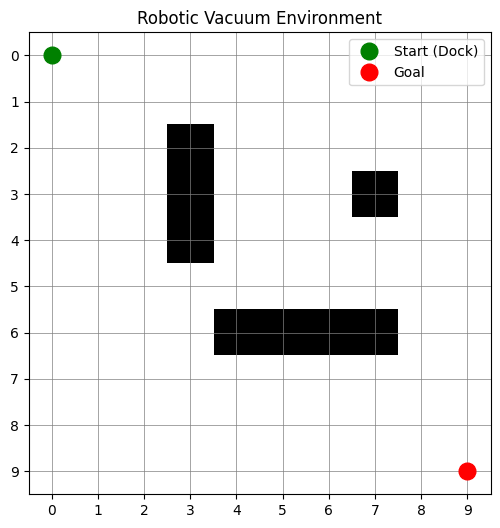

In [ ]:
grid_size = (10, 10)

grid = np.zeros(grid_size)
grid[2:5, 3] = 1
grid[6, 4:8] = 1
grid[3, 7] = 1

start_pos = (0, 0)
goal_pos = (9, 9)

def plot_grid(grid, path=None):
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.imshow(grid, cmap='binary', origin='upper')

    ax.plot(start_pos[1], start_pos[0], 'go', markersize=12, label='Start (Dock)')
    ax.plot(goal_pos[1], goal_pos[0], 'ro', markersize=12, label='Goal')

    if path:
        path_y, path_x = zip(*path)
        ax.plot(path_x, path_y, 'b-', linewidth=3, label='Vacuum Path')

    ax.set_xticks(range(grid_size[1]))
    ax.set_yticks(range(grid_size[0]))
    ax.grid(True, which='both', color='gray', linestyle='-', linewidth=0.5)
    ax.legend()
    plt.title("Robotic Vacuum Environment")
    plt.show()

plot_grid(grid)

In [ ]:
class AntColonyOptimization:
    def __init__(self, grid, start, goal, num_ants=10, generations=50, alpha=1.0, beta=2.0, evaporation_rate=0.5, Q=100):
        self.grid = grid
        self.grid_size = grid.shape
        self.start = start
        self.goal = goal
        self.num_ants = num_ants
        self.generations = generations
        self.alpha = alpha
        self.beta = beta
        self.evaporation_rate = evaporation_rate
        self.Q = Q

        self.pheromone = np.ones(self.grid_size + self.grid_size) * 0.1

    def get_valid_neighbors(self, pos):
        r, c = pos
        neighbors = []
        directions = [(-1, 0), (1, 0), (0, -1), (0, 1)]
        for dr, dc in directions:
            nr, nc = r + dr, c + dc
            if 0 <= nr < self.grid_size[0] and 0 <= nc < self.grid_size[1]:
                if self.grid[nr, nc] == 0:
                    neighbors.append((nr, nc))
        return neighbors

    def heuristic(self, pos):
        dist = abs(pos[0] - self.goal[0]) + abs(pos[1] - self.goal[1])
        return 1.0 / (dist + 0.1)

    def run(self):
        best_path = None
        best_length = float('inf')

        for gen in range(self.generations):
            all_paths = []
            for ant in range(self.num_ants):
                path = self.construct_solution()
                if path and path[-1] == self.goal:
                    all_paths.append(path)
                    if len(path) < best_length:
                        best_length = len(path)
                        best_path = path

            self.update_pheromones(all_paths)

        return best_path

    def construct_solution(self):
        path = [self.start]
        current = self.start
        visited = {self.start}

        max_steps = self.grid_size[0] * self.grid_size[1] * 2

        for _ in range(max_steps):
            if current == self.goal:
                break

            neighbors = self.get_valid_neighbors(current)
            unvisited_neighbors = [n for n in neighbors if n not in visited]

            if not unvisited_neighbors:
                break

            probabilities = []
            for neighbor in unvisited_neighbors:
                tau = self.pheromone[current[0], current[1], neighbor[0], neighbor[1]] ** self.alpha
                eta = self.heuristic(neighbor) ** self.beta
                probabilities.append(tau * eta)

            sum_prob = sum(probabilities)
            if sum_prob == 0:
                probabilities = [1.0 / len(unvisited_neighbors)] * len(unvisited_neighbors)
            else:
                probabilities = [p / sum_prob for p in probabilities]

            next_node = random.choices(unvisited_neighbors, weights=probabilities, k=1)[0]
            path.append(next_node)
            visited.add(next_node)
            current = next_node

        return path

    def update_pheromones(self, all_paths):
        self.pheromone *= (1 - self.evaporation_rate)

        for path in all_paths:
            path_length = len(path)
            deposit = self.Q / path_length
            for i in range(len(path) - 1):
                u, v = path[i], path[i+1]
                self.pheromone[u[0], u[1], v[0], v[1]] += deposit
                self.pheromone[v[0], v[1], u[0], u[1]] += deposit

Optimal path found! Total steps: 18
Path coordinates: [(0, 0), (0, 1), (1, 1), (2, 1), (2, 2), (3, 2), (4, 2), (5, 2), (5, 3), (5, 4), (5, 5), (5, 6), (5, 7), (5, 8), (5, 9), (6, 9), (7, 9), (8, 9), (9, 9)]


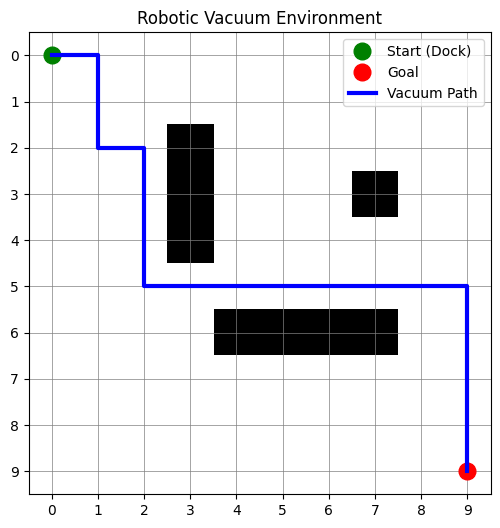

In [ ]:
aco = AntColonyOptimization(
    grid=grid,
    start=start_pos,
    goal=goal_pos,
    num_ants=15,
    generations=60,
    alpha=1.0,
    beta=3.0,
    evaporation_rate=0.4
)

optimal_path = aco.run()

if optimal_path:
    print(f"Optimal path found! Total steps: {len(optimal_path) - 1}")
    print("Path coordinates:", optimal_path)
    plot_grid(grid, path=optimal_path)
else:
    print("No valid path found by the algorithm.")